# 04 - Training pipeline (Week 5)

One function, `src.train.run()`, trains any model from `src/models.py` on any split CSV and writes
`outputs/runs/<split>/<model>/` with **best.pt**, **history.csv** and **config.json**.

Training recipe (same for every model, so the comparisons are fair):
- timm ImageNet-pretrained backbone, new 4-class classifier, channels_last memory layout
- AdamW, 1 warm-up epoch, then cosine learning-rate decay
- cross-entropy with **label smoothing 0.1** and **inverse-frequency class weights** (the clean split has only ~11% notumor)
- mixed precision (float16) with a NaN guard: on this GPU float16 sometimes gives NaN, so the run falls back to float32
- up to 20 epochs, **early stopping on validation macro-F1** (patience 5); the best epoch is kept
- on CUDA out-of-memory: halve the batch and double gradient accumulation (same effective batch)
- runs that already finished are skipped, so the notebook can be stopped and restarted

The **test** part of every split is not used here. It is kept for the final evaluation.

In [1]:
import os, sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import pandas as pd
import torch
from IPython.display import Image as ShowImage, display
from src import train
from src.models import MODELS

SPLITS = Path('outputs/splits')
PLOTS = Path('outputs/plots/week5')
print('torch', torch.__version__, '| CUDA', torch.cuda.is_available(),
      '|', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')
pd.DataFrame(MODELS).T

D:\Brain-Tumor\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


torch 2.14.1+cu126 | CUDA True | NVIDIA GeForce GTX 1650 Ti


,batch,img_size,heavy
mobilenetv3_small_100,48,224,False
efficientnet_b0,32,224,False
resnet50,24,224,True
inception_v3,24,299,True
densenet121,16,224,True
vgg16,16,224,True


## 1. Smoke test: 50 images, 1 epoch
This checks that the whole pipeline runs and writes its three files. The score means nothing with 50 images.
The first epoch is slow (several minutes) because of one-off costs: the Windows DataLoader workers start up,
and cuDNN autotunes its convolution algorithms for each new batch shape.

In [2]:
smoke = train.run('mobilenetv3_small_100', 'smoke', SPLITS / 'v1_split_clean.csv', epochs=1, subset=50)
smoke_dir = Path('outputs/runs/smoke/mobilenetv3_small_100')
print(sorted(p.name for p in smoke_dir.iterdir()))
print('finite loss:', pd.read_csv(smoke_dir / 'history.csv')[['train_loss', 'val_loss']].notna().all().all())

skipped smoke/mobilenetv3_small_100: already finished
['best.pt', 'config.json', 'history.csv']
finite loss: True


Calling it again must skip the run (this is what makes stop/resume safe):

In [3]:
_ = train.run('mobilenetv3_small_100', 'smoke', SPLITS / 'v1_split_clean.csv', epochs=1, subset=50)

skipped smoke/mobilenetv3_small_100: already finished


## 2. mobilenetv3_small_100 on the clean splits (v1 and v2)
Clean split = one image per duplicate cluster, conflicting-label clusters removed, stratified 70/15/15.

In [4]:
configs = {}
for version in ['v1', 'v2']:
    configs[f'{version}_clean'] = train.run('mobilenetv3_small_100', f'{version}_clean',
                                            SPLITS / f'{version}_split_clean.csv')

training v1_clean/mobilenetv3_small_100 (batch 48, device cuda)


D:\Brain-Tumor\src\train.py:147: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()                                  # learning rate changes after every update


  epoch  1  train loss 2.0548 acc 0.5817 | val loss 6.9532 acc 0.1154 F1 0.0517 | 160.1s  *best*


  epoch  2  train loss 0.9166 acc 0.7867 | val loss 1.2758 acc 0.4058 F1 0.3941 | 27.3s  *best*


  epoch  3  train loss 0.5957 acc 0.9129 | val loss 1.0477 acc 0.6288 F1 0.5654 | 33.5s  *best*


...

  epoch 14  train loss 0.4151 acc 0.9996 | val loss 0.4761 acc 0.9665 F1 0.9637 | 26.9s


  epoch 15  train loss 0.4144 acc 0.9984 | val loss 0.4760 acc 0.9665 F1 0.9632 | 26.9s


  epoch 16  train loss 0.4135 acc 0.9992 | val loss 0.4744 acc 0.9628 F1 0.9579 | 26.9s


  epoch 17  train loss 0.4124 acc 0.9988 | val loss 0.4765 acc 0.9665 F1 0.9609 | 27.1s


  epoch 18  train loss 0.4122 acc 0.9992 | val loss 0.4755 acc 0.9665 F1 0.9619 | 27.1s
  early stop: no val macro-F1 gain for 5 epochs


## 3. Learning curves

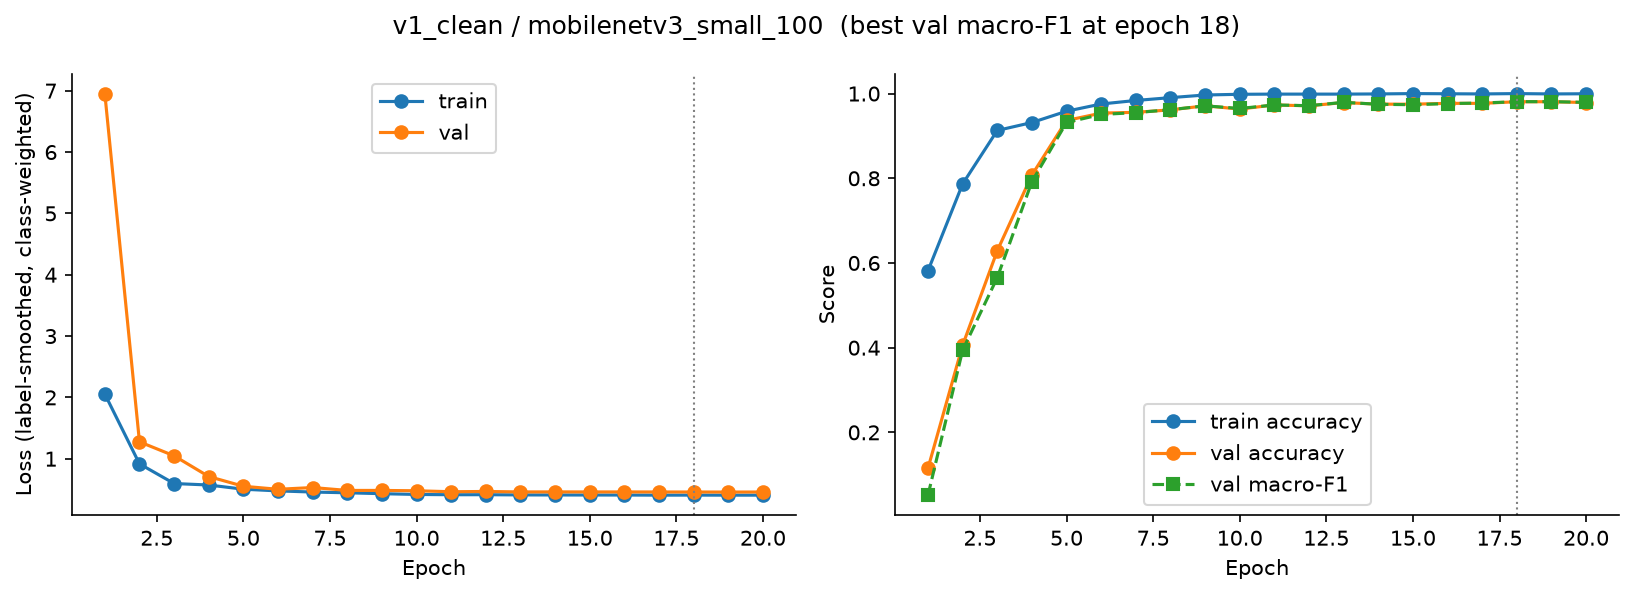

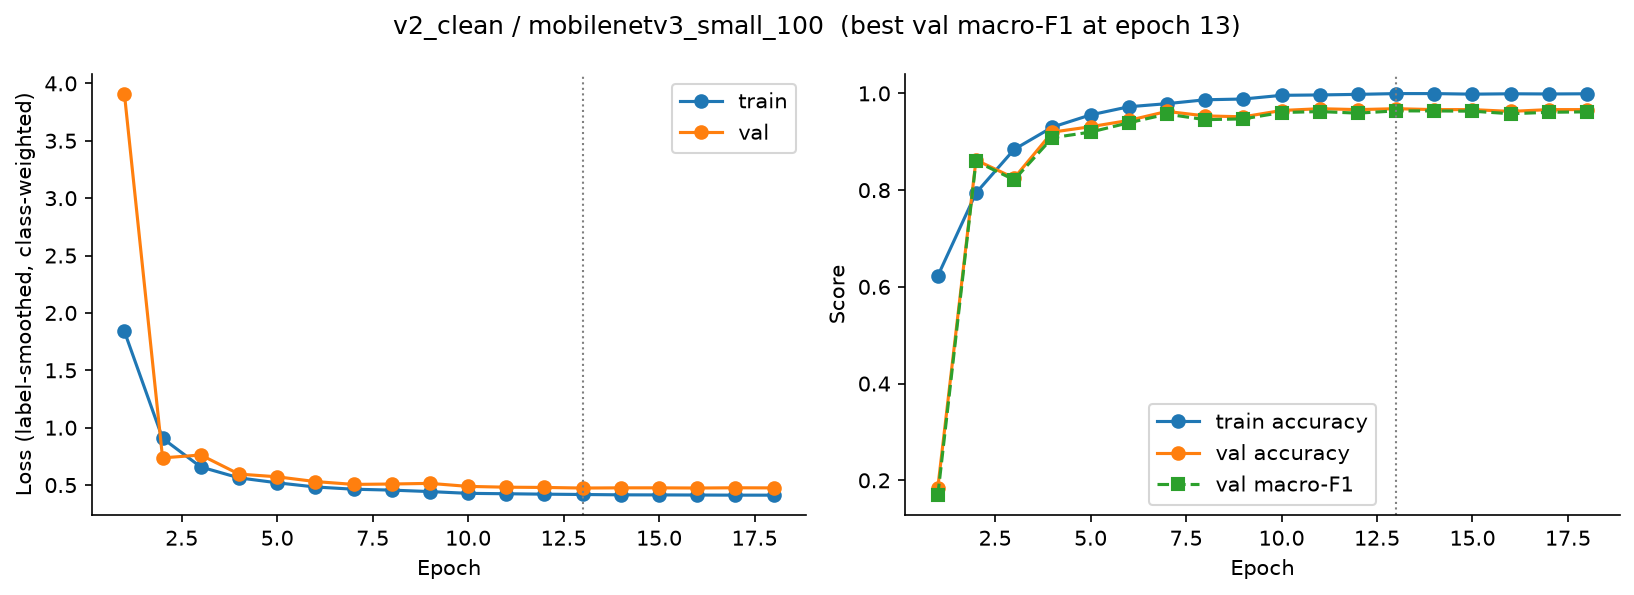

In [5]:
for split_name in configs:
    path = train.plot_history(Path('outputs/runs') / split_name / 'mobilenetv3_small_100', out_dir=PLOTS)
    display(ShowImage(str(path)))

## 4. Summary (read from config.json)

In [6]:
keys = ['epochs_run', 'best_epoch', 'best_val_macro_f1', 'batch', 'accum_steps', 'amp_disabled_at_epoch',
        'peak_gpu_mb', 'train_time_s', 'params', 'class_weights']
summary = pd.DataFrame({k: {c: v[c] for c in keys} for k, v in configs.items()}).T
summary

,epochs_run,best_epoch,best_val_macro_f1,batch,accum_steps,amp_disabled_at_epoch,peak_gpu_mb,train_time_s,params,class_weights
v1_clean,20,18,0.980924,48,1,None,690.9,674.7,1521956,"[0.7289663461538461, 0.9175491679273827, 2.173..."
v2_clean,18,13,0.963859,48,1,None,453.5,535.3,1521956,"[0.7157534246575342, 0.902158273381295, 2.28, ..."


In [7]:
# Best epoch row of each history (validation numbers only; test is untouched)
rows = []
for split_name in configs:
    h = pd.read_csv(Path('outputs/runs') / split_name / 'mobilenetv3_small_100' / 'history.csv')
    rows.append({'split': split_name, **h.loc[h['val_macro_f1'].idxmax()].to_dict()})
pd.DataFrame(rows).round(4)

,split,epoch,lr,train_loss,train_acc,val_loss,val_acc,val_macro_f1,seconds,batch,amp
0,v1_clean,18,0.0001,0.4071,1.0000,0.4577,0.9808,0.9809,25.8,48,True
1,v2_clean,13,0.0004,0.4181,0.9996,0.4743,0.9683,0.9639,26.9,48,True
